# EDA – Betrugserkennung bei Strom und Gas
**Team 5 (Roland, Leo, Tobias)** · Data Science Bootcamp-Challenge *Fraud Detection in Electricity and Gas Consumption* (STEG, Tunesien)

**Ziel:** Für jeden Kunden vorhersagen, ob er betrügt (`target = 1`) oder nicht (`target = 0`). Das ist eine binäre Klassifikation.

Rohdaten: `data/train.zip` → bereinigt: `data/fd_cleaned.csv` · Split: `data/fd_split.csv`

| # | Schritt |
|---|---|
| 1 | Setup und Daten laden |
| 2 | Erster Überblick |
| 3 | Datenbereinigung |
| 4 | Train/Test-Split |
| 5 | Zielvariable |
| 6 | Kundenmerkmale |
| 7 | Rechnungen |
| 8 | Rechnungen pro Kunde zusammenfassen |
| 9 | Betrug und kein Betrug im Vergleich |
| 10 | Bereinigte Daten speichern |
| 11 | Fazit |

## 1 · Setup und Daten laden
**Vorher einmal:** `data/train.zip` im Finder per Doppelklick entpacken. Danach gibt es den Ordner `data/train/` mit `client_train.csv` und `invoice_train.csv`. Die entpackten CSVs landen wegen `.gitignore` nicht auf GitHub.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 1

DATA_DIR = Path("data")
TRAIN_DIR = DATA_DIR / "train"

In [2]:
print("Daten entpackt:", (TRAIN_DIR / "client_train.csv").exists())

# counter_statue hat gemischte Typen (Zahlen und Text), deshalb erstmal als Text einlesen
df_client = pd.read_csv(TRAIN_DIR / "client_train.csv")
df_invoice = pd.read_csv(TRAIN_DIR / "invoice_train.csv", dtype={"counter_statue": str})

print("Kunden:    ", df_client.shape)
print("Rechnungen:", df_invoice.shape)

Daten entpackt: True
Kunden:     (135493, 6)
Rechnungen: (4476749, 16)


## 2 · Erster Überblick
### Kunden

In [3]:
display(df_client.head())
df_client.info()

,disrict,client_id,client_catg,region,creation_date,target
0,60,train_Client_0,11,101,31/12/1994,0.0
1,69,train_Client_1,11,107,29/05/2002,0.0
2,62,train_Client_10,11,301,13/03/1986,0.0
3,69,train_Client_100,11,105,11/07/1996,0.0
4,62,train_Client_1000,11,303,14/10/2014,0.0


<class 'pandas.DataFrame'>
RangeIndex: 135493 entries, 0 to 135492
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   disrict        135493 non-null  int64  
 1   client_id      135493 non-null  str    
 2   client_catg    135493 non-null  int64  
 3   region         135493 non-null  int64  
 4   creation_date  135493 non-null  str    
 5   target         135493 non-null  float64
dtypes: float64(1), int64(3), str(2)
memory usage: 6.2 MB


**Was fällt auf?**
* Eine Zeile pro Kunde, `client_id` verbindet die Kunden mit den Rechnungen.
* `disrict` (so falsch geschrieben im Original), `client_catg` und `region` sind Zahlen, aber eigentlich **Kategorien**. Ein Mittelwert davon macht keinen Sinn.
* `creation_date` ist Text und muss ein Datum werden.
* `target` ist eine Kommazahl (`0.0` / `1.0`), soll aber `int` sein.

### Rechnungen

In [4]:
display(df_invoice.head())
df_invoice.info()

,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,train_Client_0,2014-03-24,11,1335667,0,203,8,1,82,0,0,0,14302,14384,4,ELEC
1,train_Client_0,2013-03-29,11,1335667,0,203,6,1,1200,184,0,0,12294,13678,4,ELEC
2,train_Client_0,2015-03-23,11,1335667,0,203,8,1,123,0,0,0,14624,14747,4,ELEC
3,train_Client_0,2015-07-13,11,1335667,0,207,8,1,102,0,0,0,14747,14849,4,ELEC
4,train_Client_0,2016-11-17,11,1335667,0,207,9,1,572,0,0,0,15066,15638,12,ELEC


<class 'pandas.DataFrame'>
RangeIndex: 4476749 entries, 0 to 4476748
Data columns (total 16 columns):
 #   Column                Dtype
---  ------                -----
 0   client_id             str  
 1   invoice_date          str  
 2   tarif_type            int64
 3   counter_number        int64
 4   counter_statue        str  
 5   counter_code          int64
 6   reading_remarque      int64
 7   counter_coefficient   int64
 8   consommation_level_1  int64
 9   consommation_level_2  int64
 10  consommation_level_3  int64
 11  consommation_level_4  int64
 12  old_index             int64
 13  new_index             int64
 14  months_number         int64
 15  counter_type          str  
dtypes: int64(12), str(4)
memory usage: 546.5 MB


**Was fällt auf?**
* Eine Zeile pro Rechnung (genauer: pro Ablesung eines Zählers).
* Auch hier sind viele Zahlen eigentlich Codes: `tarif_type`, `counter_number`, `counter_statue`, `counter_code`, `reading_remarque`.
* Echte Mengen: die vier `consommation_level_*` (Verbrauch je Tarifstufe), `old_index` / `new_index` (Zählerstand vorher / nachher) und `months_number` (Monate pro Rechnung).
* `counter_type` ist `ELEC` (Strom) oder `GAZ` (Gas).

### Wie hängen die Tabellen zusammen?
Das `target` steht beim Kunden, die meisten Infos stehen in den Rechnungen. Wir prüfen, ob jeder Kunde Rechnungen hat und ob es Rechnungen ohne Kunden gibt.

In [5]:
client_ids = set(df_client["client_id"])
invoice_ids = set(df_invoice["client_id"])

print("Kunden ohne Rechnung: ", len(client_ids - invoice_ids))
print("Rechnungen ohne Kunde:", len(invoice_ids - client_ids))

df_invoice.groupby("client_id").size().describe()

Kunden ohne Rechnung:  0
Rechnungen ohne Kunde: 0


count    135493.000000
mean         33.040445
std          26.092229
min           1.000000
25%          10.000000
50%          30.000000
75%          50.000000
max         439.000000
dtype: float64

**Was fällt auf?**
* Alles passt zusammen: kein Kunde ohne Rechnung, keine Rechnung ohne Kunde.
* Ein Kunde hat im Median 30 Rechnungen, manche nur eine, einzelne über 400. Das ist eine **1-zu-n-Beziehung**.

**Entscheidung:** Wir hängen die Kunden nicht einfach an jede Rechnung (das wären 4,5 Mio. Zeilen). Stattdessen fassen wir die Rechnungen **pro Kunde** zusammen und verbinden das dann 1-zu-1 mit den Kunden (Abschnitt 8).

## 3 · Datenbereinigung
### 3.1 Fehlende Werte und Duplikate

In [6]:
print("Fehlende Werte Kunden:    ", df_client.isna().sum().sum())
print("Fehlende Werte Rechnungen:", df_invoice.isna().sum().sum())
print("Doppelte client_id:       ", df_client["client_id"].duplicated().sum())
print("Doppelte Rechnungen:      ", df_invoice.duplicated().sum())

Fehlende Werte Kunden:     0
Fehlende Werte Rechnungen: 0
Doppelte client_id:        0
Doppelte Rechnungen:       11


In [7]:
# Die doppelten Rechnungen ansehen, bevor wir sie löschen
df_invoice[df_invoice.duplicated(keep=False)].sort_values(["client_id", "invoice_date"]).head(6)

,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
951890,train_Client_125864,2011-12-12,11,101545,5,413,6,1,0,0,0,0,13680,13680,2,ELEC
951893,train_Client_125864,2011-12-12,11,101545,5,413,6,1,0,0,0,0,13680,13680,2,ELEC
1755789,train_Client_25894,2010-07-13,40,6986740,5,5,6,1,0,0,0,0,0,0,2,GAZ
1755798,train_Client_25894,2010-07-13,40,6986740,5,5,6,1,0,0,0,0,0,0,2,GAZ
2137995,train_Client_3636,2012-01-18,40,312650,5,5,6,1,0,0,0,0,623,623,2,GAZ
2137999,train_Client_3636,2012-01-18,40,312650,5,5,6,1,0,0,0,0,623,623,2,GAZ


**Was fällt auf?**
* Es gibt keine fehlenden Werte. Das heißt aber nicht, dass alles stimmt: Fehler können sich auch als 0 oder als unmöglicher Wert verstecken (siehe 3.3).
* 11 Rechnungen sind in **allen** Spalten gleich. Das sind Erfassungsfehler, wir löschen sie.

In [8]:
df_invoice = df_invoice.drop_duplicates().reset_index(drop=True)
df_invoice.shape

(4476738, 16)

### 3.2 Datentypen
`target` wird `int`, die beiden Datumsspalten werden `datetime`.

In [9]:
df_client["target"] = df_client["target"].astype(int)
df_client["creation_date"] = pd.to_datetime(df_client["creation_date"], format="%d/%m/%Y")
df_invoice["invoice_date"] = pd.to_datetime(df_invoice["invoice_date"], format="%Y-%m-%d")

print("Vertragsbeginn:", df_client["creation_date"].min().date(), "bis", df_client["creation_date"].max().date())
print("Rechnungen:    ", df_invoice["invoice_date"].min().date(), "bis", df_invoice["invoice_date"].max().date())

Vertragsbeginn: 1977-02-05 bis 2019-09-10
Rechnungen:     1977-06-09 bis 2019-12-07


Beide Datumsspalten ließen sich mit festem Format umwandeln, es gibt also keine gemischten Datumsformate.

Jetzt `counter_statue` (Zustand des Zählers):

In [10]:
df_invoice["counter_statue"].value_counts()

counter_statue
0         4379008
1           74036
5           20628
4            2729
3             258
2              32
46             14
A              13
618            12
769             6
269375          1
420             1
Name: count, dtype: int64

**Was fällt auf?**
* Fast alle Werte sind `0` bis `5` (laut Zindi verschiedene Zählerzustände).
* Dazu kommen ein paar Werte wie `46`, `618`, `269375` oder `A`, zusammen nur 47 Zeilen. Das sind wahrscheinlich Tippfehler.

**Entscheidung:** Alles außer `0` bis `5` setzen wir auf `NaN` (unbekannt).

In [11]:
gueltig = ["0", "1", "2", "3", "4", "5"]
df_invoice.loc[~df_invoice["counter_statue"].isin(gueltig), "counter_statue"] = np.nan
df_invoice["counter_statue"] = df_invoice["counter_statue"].astype(float)

df_invoice["counter_statue"].value_counts(dropna=False)

counter_statue
0.0    4379008
1.0      74036
5.0      20628
4.0       2729
3.0        258
NaN         47
2.0         32
Name: count, dtype: int64

### 3.3 Unplausible Werte
Überblick über die Spalten, die echte Mengen enthalten:

In [12]:
mengen = ["consommation_level_1", "consommation_level_2", "consommation_level_3",
          "consommation_level_4", "old_index", "new_index", "months_number", "counter_coefficient"]

display(df_invoice[mengen].describe().T)

# 99 % der Werte liegen unter dieser Grenze
df_invoice[mengen].quantile(0.99)

,count,mean,std,min,25%,50%,75%,max
consommation_level_1,4476738.0,410.980505,757.308655,0.0,79.0,274.0,600.0,999910.0
consommation_level_2,4476738.0,109.322745,1220.124822,0.0,0.0,0.0,0.0,999073.0
consommation_level_3,4476738.0,20.306254,157.424128,0.0,0.0,0.0,0.0,64492.0
consommation_level_4,4476738.0,52.926011,875.473549,0.0,0.0,0.0,0.0,547946.0
old_index,4476738.0,17767.007271,40366.950821,0.0,1791.0,7690.0,21660.0,2800280.0
new_index,4476738.0,18349.715070,40953.232393,0.0,2056.0,8192.0,22343.0,2870972.0
months_number,4476738.0,44.831052,3128.339228,0.0,4.0,4.0,4.0,636624.0
counter_coefficient,4476738.0,1.003040,0.308347,0.0,1.0,1.0,1.0,50.0


consommation_level_1      2192.00
consommation_level_2      2069.00
consommation_level_3       800.00
consommation_level_4      1222.00
old_index               150959.78
new_index               155668.26
months_number               12.00
counter_coefficient          1.00
Name: 0.99, dtype: float64

**Was fällt auf?**
* `months_number`: Median 4 Monate, das Maximum liegt aber bei über 600.000 Monaten. Das ist unmöglich.
* Verbrauch: 99 % der Werte sind klein, das Maximum liegt aber bei fast 1 Mio. Das sieht nach Fehlern aus.
* `counter_coefficient` ist fast immer 1.

In [13]:
zu_lang = df_invoice["months_number"] > 24
print(f"Rechnungen über 24 Monate: {zu_lang.sum():,} ({zu_lang.mean():.2%})")

df_invoice["months_number"].value_counts().head(8)

Rechnungen über 24 Monate: 3,528 (0.08%)


months_number
4     3680478
8      278772
2      270898
1      113266
12      54328
6       34678
16      11550
3        7286
Name: count, dtype: int64

Fast 4 von 5 Rechnungen gehen über 4 Monate. Nur unter 0,1 % gehen über 2 Jahre. Wir nutzen `months_number` unten nicht für Berechnungen, deshalb lassen wir die Werte so.

**Verbrauch prüfen:** Eigentlich gilt Verbrauch = neuer Zählerstand − alter Zählerstand. Und der Gesamtverbrauch ist die Summe der vier Tarifstufen.

In [14]:
stufen = ["consommation_level_1", "consommation_level_2", "consommation_level_3", "consommation_level_4"]
df_invoice["consumption"] = df_invoice[stufen].sum(axis=1)
differenz = df_invoice["new_index"] - df_invoice["old_index"]

print(f"Summe der Stufen = Differenz Zählerstand: {(df_invoice['consumption'] == differenz).mean():.2%}")
print(f"Zählerstand rückwärts (new < old):        {(differenz < 0).sum():,}")
print(f"Verbrauch = 0:                            {(df_invoice['consumption'] == 0).mean():.2%}")
print(f"Verbrauch negativ:                        {(df_invoice['consumption'] < 0).sum():,}")

Summe der Stufen = Differenz Zählerstand: 99.58%
Zählerstand rückwärts (new < old):        2,264
Verbrauch = 0:                            10.44%
Verbrauch negativ:                        0


**Was fällt auf?**
* Bei 99,6 % passt es genau. Wir dürfen die vier Stufen also zu einem Gesamtverbrauch `consumption` addieren.
* Negativen Verbrauch gibt es nicht.
* Bei gut 2.000 Rechnungen läuft der Zählerstand **rückwärts**. Das passiert bei Zählertausch, Ablesefehler oder Manipulation. Das schauen wir uns später beim Betrug an.
* Gut 10 % der Rechnungen haben Verbrauch 0 (z. B. leere Wohnung).

In [15]:
# Die größten Verbrauchswerte ansehen
df_invoice.nlargest(8, "consumption")[["client_id", "invoice_date", "counter_type",
                                       "old_index", "new_index", "consumption", "months_number"]]

,client_id,invoice_date,counter_type,old_index,new_index,consumption,months_number
2571803,train_Client_48203,2012-03-04,GAZ,138660,138570,999910,2
2873940,train_Client_56441,2012-03-04,ELEC,224454,224127,999673,2
502067,train_Client_113523,2012-01-02,ELEC,183478,4564,821086,4
3092568,train_Client_62387,2012-06-02,ELEC,266056,53013,786957,4
2907949,train_Client_5737,2012-06-02,ELEC,222657,8569,785912,4
3479819,train_Client_72985,2017-03-05,ELEC,0,548946,548946,2
221446,train_Client_105976,2016-02-06,ELEC,0,344568,344568,2
221432,train_Client_105976,2018-02-11,ELEC,1942940,2229705,286765,4


**Was fällt auf?**
* Die größten Werte sind keine echten Verbräuche. Der Zähler ist bei 999.999 "übergelaufen" und wieder bei 0 angefangen, oder der alte Zählerstand fehlt (0).

**Entscheidung:** Wir löschen die Zeilen nicht, weil wir nicht sicher wissen, was passiert ist. Pro Kunde nehmen wir später den **Median** statt dem Mittelwert, weil der Median von solchen Ausreißern kaum beeinflusst wird.

## 4 · Train/Test-Split
Bevor wir uns anschauen, was mit Betrug zusammenhängt, teilen wir die Daten auf. Sonst würden wir Entscheidungen auch mit den Testdaten treffen (Data Leakage).

* Wir teilen **nach Kunden** auf, nicht nach Rechnungen. Sonst wäre derselbe Kunde in Train und Test.
* **stratify** nach `target`, damit beide Teile gleich viel Betrug haben.
* 80 % Train, 20 % Test, `random_state = 1`.

Der Split wird als `data/fd_split.csv` gespeichert, damit alle im Team denselben benutzen.

In [16]:
SPLIT_PATH = DATA_DIR / "fd_split.csv"

train_ids, test_ids = train_test_split(
    df_client["client_id"],
    test_size=0.2,
    stratify=df_client["target"],
    random_state=RANDOM_STATE,
)

df_train = df_client[df_client["client_id"].isin(train_ids)].copy()
df_test = df_client[df_client["client_id"].isin(test_ids)].copy()

print(f"Train: {len(df_train):,} Kunden, Betrug {df_train['target'].mean():.2%}")
print(f"Test:  {len(df_test):,} Kunden, Betrug {df_test['target'].mean():.2%}")
print("Kunden in beiden Teilen:", len(set(train_ids) & set(test_ids)))

Train: 108,394 Kunden, Betrug 5.58%
Test:  27,099 Kunden, Betrug 5.58%
Kunden in beiden Teilen: 0


In [17]:
# Split speichern: eine Zeile pro Kunde mit "train" oder "test"
df_split = df_client[["client_id"]].copy()
df_split["split"] = "test"
df_split.loc[df_split["client_id"].isin(train_ids), "split"] = "train"

# Einen gespeicherten Split nicht aus Versehen überschreiben
if SPLIT_PATH.exists():
    gespeichert = pd.read_csv(SPLIT_PATH)
    print("Split ist gleich wie gespeichert:", gespeichert.equals(df_split))
else:
    df_split.to_csv(SPLIT_PATH, index=False)
    print("Gespeichert:", SPLIT_PATH)

Gespeichert: data/fd_split.csv


Beide Teile haben dieselbe Betrugsquote und kein Kunde ist doppelt. **Ab hier schauen wir uns den Zusammenhang mit `target` nur im Train-Teil an.** Den Test-Teil benutzen wir erst ganz am Ende für die Bewertung des Modells.

## 5 · Zielvariable

target
0    102341
1      6053
Name: count, dtype: int64

Betrugsquote: 5.58%


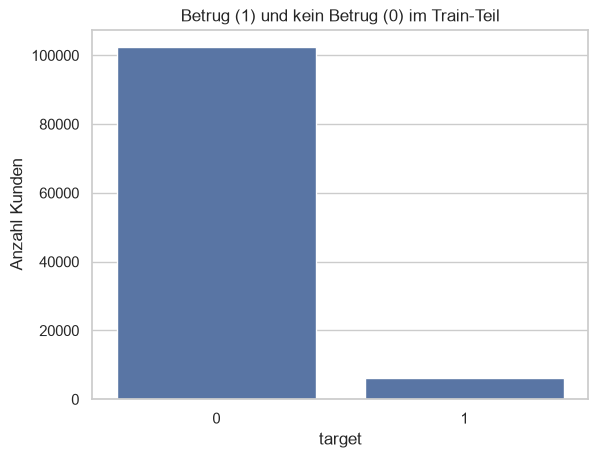

In [18]:
print(df_train["target"].value_counts())
print(f"\nBetrugsquote: {df_train['target'].mean():.2%}")

sns.countplot(data=df_train, x="target")
plt.title("Betrug (1) und kein Betrug (0) im Train-Teil")
plt.xlabel("target")
plt.ylabel("Anzahl Kunden")
plt.show()

**Was fällt auf?**
* Nur etwa 5,6 % der Kunden betrügen. Die Klassen sind stark **unausgewogen (imbalanced)**.

Was passiert, wenn ein "Modell" einfach immer "kein Betrug" sagt?

In [19]:
y_true = df_train["target"]
y_immer_0 = np.zeros(len(y_true))

print(f"Accuracy: {accuracy_score(y_true, y_immer_0):.1%}")
print(f"Recall:   {recall_score(y_true, y_immer_0):.1%}")
print(f"ROC-AUC:  {roc_auc_score(y_true, y_immer_0):.2f}")

Accuracy: 94.4%
Recall:   0.0%
ROC-AUC:  0.50


94 % Accuracy, aber kein einziger Betrüger gefunden.

**Entscheidung:**
* Accuracy ist hier keine gute Metrik.
* Wir nehmen **ROC-AUC** als Hauptmetrik (0,5 = Zufall, 1 = perfekt). Dazu **Recall** (wie viele Betrüger finden wir?) und **Precision** (wie viele Verdachtsfälle stimmen wirklich?).
* Beim Training probieren wir `class_weight="balanced"` aus.

## 6 · Kundenmerkmale
Für jedes Merkmal schauen wir: **Wie hoch ist die Betrugsquote pro Gruppe?** Die gestrichelte Linie ist die Betrugsquote insgesamt. Die schwarzen Striche auf den Balken zeigen, wie sicher der Wert ist (95-%-Konfidenzintervall). Kleine Gruppen haben lange Striche.

In [20]:
betrugsquote = df_train["target"].mean()


def plot_betrugsquote(df, spalte, titel):
    # Balken = Betrugsquote je Gruppe, Linie = Betrugsquote insgesamt
    plt.figure(figsize=(10, 4))
    sns.barplot(data=df, x=spalte, y="target", color="tab:blue")
    plt.axhline(betrugsquote, color="black", linestyle="--", label="Betrugsquote gesamt")
    plt.title(titel)
    plt.ylabel("Betrugsquote")
    plt.legend()
    plt.show()


def tabelle_betrugsquote(df, spalte):
    # Anzahl Kunden und Betrugsquote je Gruppe
    tabelle = df.groupby(spalte)["target"].agg(["count", "mean"])
    tabelle.columns = ["Kunden", "Betrugsquote"]
    return tabelle.round(3)

### 6.1 Bezirk (`disrict`)

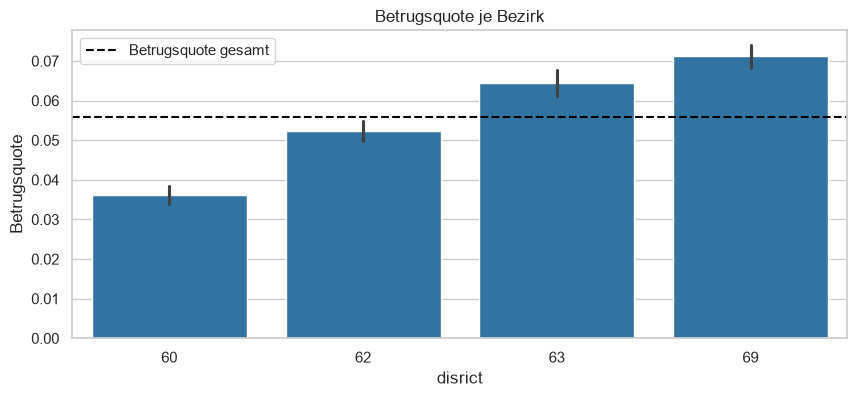

,Kunden,Betrugsquote
disrict,,
60,25625,0.036
62,32217,0.052
63,23193,0.065
69,27359,0.071


In [21]:
plot_betrugsquote(df_train, "disrict", "Betrugsquote je Bezirk")
tabelle_betrugsquote(df_train, "disrict")

**Was fällt auf?**
* Nur vier Bezirke, alle mit über 20.000 Kunden.
* Die Betrugsquote geht von 3,6 % (Bezirk 60) bis 7,1 % (Bezirk 69), also etwa das Doppelte. Der Bezirk ist ein brauchbares Merkmal.

### 6.2 Kundenkategorie (`client_catg`)

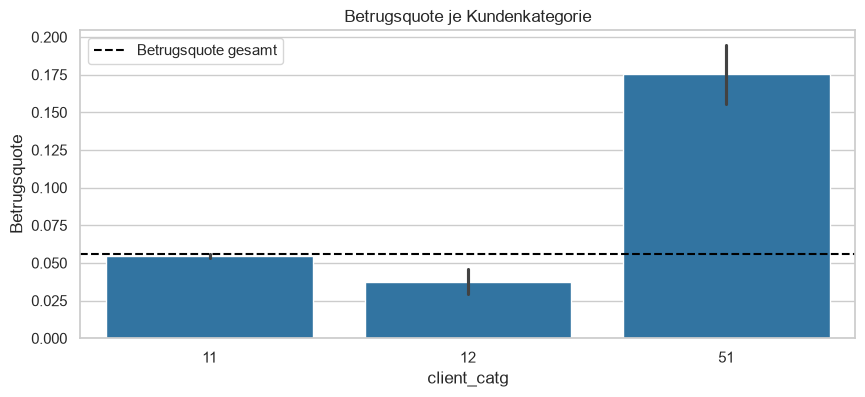

,Kunden,Betrugsquote
client_catg,,
11,105176,0.055
12,1888,0.038
51,1330,0.175


In [22]:
plot_betrugsquote(df_train, "client_catg", "Betrugsquote je Kundenkategorie")
tabelle_betrugsquote(df_train, "client_catg")

**Was fällt auf?**
* Kategorie 11 sind fast alle Kunden (97 %).
* **Kategorie 51 hat 17,5 % Betrug**, das ist dreimal so viel wie im Schnitt. Mit 1.330 Kunden ist die Gruppe auch groß genug, dass das kein Zufall ist.
* Was Kategorie 51 genau bedeutet, steht nicht in den Daten.

### 6.3 Region (`region`)

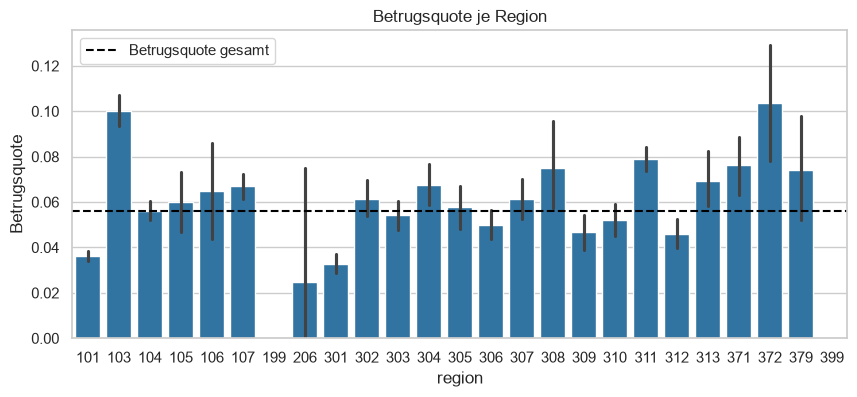

,Kunden,Betrugsquote
region,,
199,1,0.000
206,40,0.025
399,129,0.000
379,460,0.074
372,511,0.104


In [23]:
plot_betrugsquote(df_train, "region", "Betrugsquote je Region")
tabelle_betrugsquote(df_train, "region").sort_values("Kunden").head(5)

**Was fällt auf?**
* 25 Regionen, manche sind sehr klein (Region 199 hat nur 1 Kunden). Bei so kleinen Gruppen sagt die Betrugsquote nichts aus, das sieht man an den langen Strichen.
* Bei den großen Regionen gibt es echte Unterschiede: Region 101 (größte Region) hat 3,6 %, Region 103 hat 10 %.

**Entscheidung:** Region als Kategorie benutzen (One-Hot-Encoding), kleine Regionen zu "Sonstige" zusammenfassen.

Hängen Region und Bezirk zusammen? Die erste Ziffer der Region könnte eine Gruppe sein.

In [24]:
pd.crosstab(df_train["region"] // 100, df_train["disrict"])

disrict,60,62,63,69
region,,,,
1,25625,0,1481,27319
2,0,0,0,40
3,0,32217,21712,0


**Was fällt auf?**
* Die Regionen 1xx liegen in den Bezirken 60, 63 und 69, die Regionen 3xx in 62 und 63. Die Region ist also eine feinere Einteilung innerhalb der Bezirke.
* Beide Spalten enthalten damit zum Teil dieselbe Information. Für die logistische Regression müssen wir das im Kopf behalten.

### 6.4 Vertragsbeginn (`creation_date`)
Wir rechnen aus, wie lange jemand schon Kunde ist. Als Stichtag nehmen wir die letzte Rechnung im Datensatz (die Daten enden 2019).

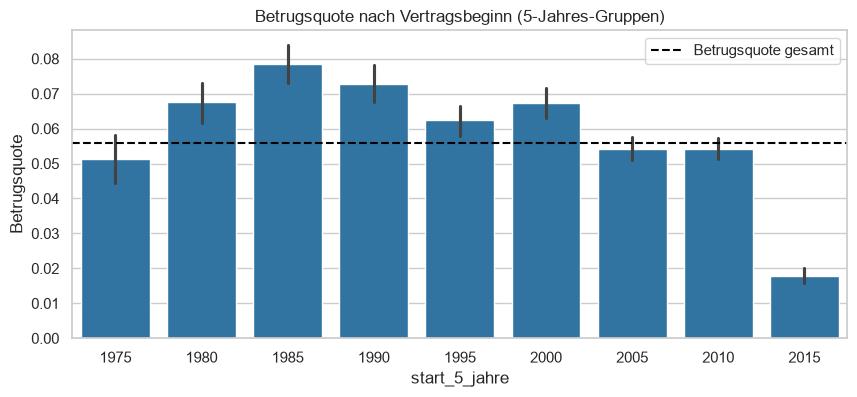

,Kunden,Betrugsquote
start_5_jahre,,
1975,3915,0.051
1980,7623,0.068
1985,8613,0.078
1990,8973,0.073
1995,10364,0.062
2000,13566,0.067
2005,18183,0.054
2010,22001,0.054
2015,15156,0.018


In [25]:
STICHTAG = df_invoice["invoice_date"].max()

df_train["contract_age_years"] = (STICHTAG - df_train["creation_date"]).dt.days / 365.25
df_train["start_5_jahre"] = (df_train["creation_date"].dt.year // 5) * 5

plot_betrugsquote(df_train, "start_5_jahre", "Betrugsquote nach Vertragsbeginn (5-Jahres-Gruppen)")
tabelle_betrugsquote(df_train, "start_5_jahre")

**Was fällt auf?**
* Kunden mit Vertragsbeginn **ab 2015 haben nur 1,8 % Betrug**. Alle älteren Gruppen liegen zwischen 5 und 8 %.
* Eine mögliche Erklärung: `target = 1` heißt eigentlich "bei einer Kontrolle erwischt". Neue Kunden hatten weniger Zeit, kontrolliert zu werden. `target = 0` heißt also eher "nicht erwischt" als "ehrlich".

**Entscheidung:** Das Vertragsalter (`contract_age_years`) als Feature nutzen.

## 7 · Rechnungen
Hier beschreiben wir nur die Rechnungen selbst, ohne `target`. Deshalb dürfen wir alle Rechnungen benutzen.

### 7.1 Zeitraum

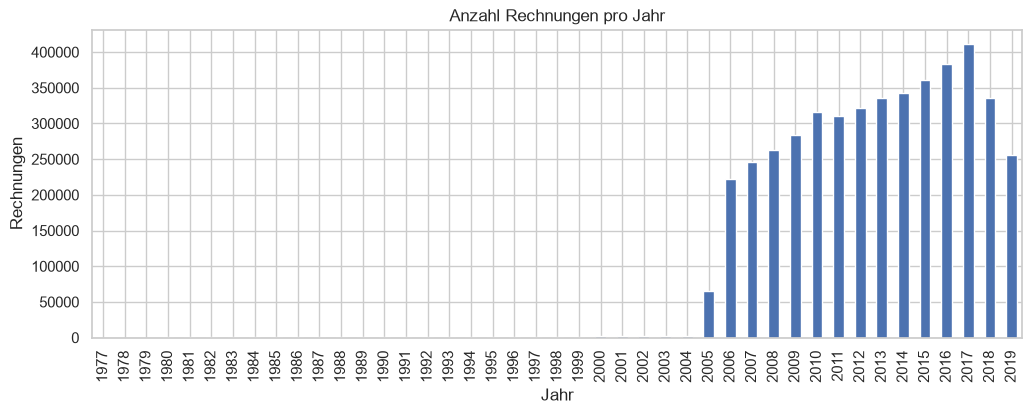

Rechnungen vor 2005: 0.49%


In [26]:
rechnungen_pro_jahr = df_invoice["invoice_date"].dt.year.value_counts().sort_index()

rechnungen_pro_jahr.plot(kind="bar", figsize=(12, 4))
plt.title("Anzahl Rechnungen pro Jahr")
plt.xlabel("Jahr")
plt.ylabel("Rechnungen")
plt.show()

print(f"Rechnungen vor 2005: {(df_invoice['invoice_date'].dt.year < 2005).mean():.2%}")

**Was fällt auf?**
* Die Rechnungen fangen praktisch erst **2005** an, davor gibt es fast keine. 2019 ist nicht vollständig.
* Ein Kunde mit Vertrag von 1985 hat also trotzdem nur Rechnungen ab etwa 2005.

### 7.2 Strom und Gas

In [27]:
print(df_invoice["counter_type"].value_counts(normalize=True).round(3))

# Welche Zählertypen hat ein Kunde?
kunden_strom = set(df_invoice.loc[df_invoice["counter_type"] == "ELEC", "client_id"])
kunden_gas = set(df_invoice.loc[df_invoice["counter_type"] == "GAZ", "client_id"])
anzahl_kunden = df_invoice["client_id"].nunique()

print(f"nur Strom:      {len(kunden_strom - kunden_gas) / anzahl_kunden:.1%}")
print(f"Strom und Gas:  {len(kunden_strom & kunden_gas) / anzahl_kunden:.1%}")
print(f"nur Gas:        {len(kunden_gas - kunden_strom) / anzahl_kunden:.1%}")

counter_type
ELEC    0.688
GAZ     0.312
Name: proportion, dtype: float64
nur Strom:      54.2%
Strom und Gas:  45.3%
nur Gas:        0.5%


**Was fällt auf?**
* Gut zwei Drittel der Rechnungen sind Strom, knapp ein Drittel Gas.
* Etwa 54 % der Kunden haben nur Strom, gut 45 % haben Strom und Gas. Reine Gaskunden gibt es kaum.

### 7.3 Verteilung des Verbrauchs

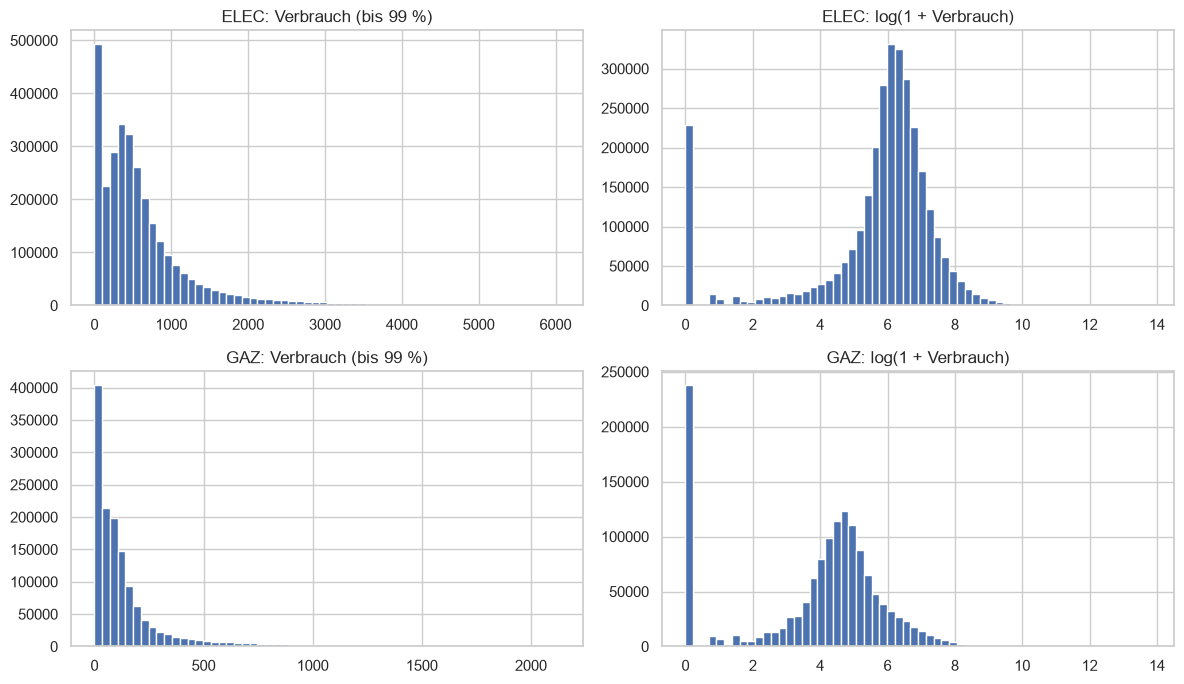

,count,mean,std,min,25%,50%,75%,max
counter_type,,,,,,,,
ELEC,3079398.0,772.505840,2006.862824,0.0,221.0,460.0,820.0,999673.0
GAZ,1397340.0,199.128385,997.339944,0.0,24.0,85.0,173.0,999910.0


In [28]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for i, typ in enumerate(["ELEC", "GAZ"]):
    verbrauch = df_invoice.loc[df_invoice["counter_type"] == typ, "consumption"]
    grenze = verbrauch.quantile(0.99)

    axes[i, 0].hist(verbrauch[verbrauch <= grenze], bins=60)
    axes[i, 0].set_title(f"{typ}: Verbrauch (bis 99 %)")

    axes[i, 1].hist(np.log1p(verbrauch), bins=60)
    axes[i, 1].set_title(f"{typ}: log(1 + Verbrauch)")

plt.tight_layout()
plt.show()

df_invoice.groupby("counter_type")["consumption"].describe()

**Was fällt auf?**
* Der Verbrauch ist stark **rechtsschief**: viele kleine Werte, wenige sehr große. Der Mittelwert liegt deutlich über dem Median.
* Mit `log(1 + x)` sieht die Verteilung viel normaler aus. Der Balken ganz links sind die Rechnungen mit Verbrauch 0.
* Gas hat einen viel kleineren Verbrauch als Strom.

**Entscheidung:** Strom und Gas getrennt zusammenfassen. Für die logistische Regression den Verbrauch logarithmieren.

### 7.4 Tarif und Bemerkung des Ablesers

In [29]:
pd.crosstab(df_invoice["tarif_type"], df_invoice["counter_type"])

counter_type,ELEC,GAZ
tarif_type,,
8,43,0
9,6039,0
10,276210,0
11,2679864,0
12,11345,0
13,11656,0
14,11611,0
15,72422,0
18,4,0


In [30]:
df_invoice["reading_remarque"].value_counts()

reading_remarque
6      2230928
9      1416992
8       828123
7          661
203         15
413         12
207          6
5            1
Name: count, dtype: int64

**Was fällt auf?**
* Jeder Tarif gehört entweder nur zu Strom oder nur zu Gas.
* Bei `reading_remarque` gibt es drei große Codes (6, 8, 9) und ein paar seltene Werte. Die seltenen sehen aus wie Werte aus `counter_code`, also wahrscheinlich in die falsche Spalte gerutscht.

## 8 · Rechnungen pro Kunde zusammenfassen
Jetzt bauen wir eine Tabelle mit **einer Zeile pro Kunde**. Dafür berechnen wir aus den Rechnungen ein paar einfache Kennzahlen pro Kunde. Das ist kein Leakage, weil wir dafür kein `target` benutzen.

Vorher legen wir Hilfsspalten an (0 oder 1), damit wir danach einfach den Mittelwert (= Anteil) nehmen können.

In [31]:
df_invoice["is_gas"] = (df_invoice["counter_type"] == "GAZ").astype(int)
df_invoice["is_zero"] = (df_invoice["consumption"] == 0).astype(int)
df_invoice["index_backwards"] = (df_invoice["new_index"] < df_invoice["old_index"]).astype(int)
df_invoice["statue_not_ok"] = (df_invoice["counter_statue"] != 0).astype(int)  # NaN zählt auch als nicht ok

df_agg = df_invoice.groupby("client_id").agg(
    n_invoices=("invoice_date", "count"),
    n_counters=("counter_number", "nunique"),
    share_gas=("is_gas", "mean"),
    share_zero=("is_zero", "mean"),
    any_index_backwards=("index_backwards", "max"),
    share_statue_not_ok=("statue_not_ok", "mean"),
    first_invoice=("invoice_date", "min"),
    last_invoice=("invoice_date", "max"),
)
df_agg.head()

,n_invoices,n_counters,share_gas,share_zero,any_index_backwards,share_statue_not_ok,first_invoice,last_invoice
client_id,,,,,,,,
train_Client_0,35,1,0.0,0.0,0,0.0,2005-10-17,2019-03-19
train_Client_1,37,1,0.0,0.0,0,0.0,2005-10-19,2019-04-02
train_Client_10,18,1,0.0,0.0,0,0.0,2005-11-10,2019-05-02
train_Client_100,20,1,0.0,0.8,0,0.0,2005-06-10,2012-09-25
train_Client_1000,14,1,0.0,0.0,0,0.0,2015-02-13,2019-06-17


In [32]:
# Verbrauch getrennt für Strom und Gas
df_strom = df_invoice[df_invoice["counter_type"] == "ELEC"].groupby("client_id")["consumption"].agg(["median", "mean", "std"])
df_strom.columns = ["cons_median_elec", "cons_mean_elec", "cons_std_elec"]

df_gas = df_invoice[df_invoice["counter_type"] == "GAZ"].groupby("client_id")["consumption"].agg(["median", "mean", "std"])
df_gas.columns = ["cons_median_gaz", "cons_mean_gaz", "cons_std_gaz"]

df_gas.head()

,cons_median_gaz,cons_mean_gaz,cons_std_gaz
client_id,,,
train_Client_10000,70.0,245.315789,259.190846
train_Client_100000,25.5,91.650000,139.262824
train_Client_100001,119.5,118.368421,59.176521
train_Client_100004,109.0,103.200000,44.234602
train_Client_100005,264.5,335.210526,261.838010


In [33]:
df_merged = df_client.merge(df_agg, on="client_id", how="left")
df_merged = df_merged.merge(df_strom, on="client_id", how="left")
df_merged = df_merged.merge(df_gas, on="client_id", how="left")

df_merged["contract_age_years"] = (STICHTAG - df_merged["creation_date"]).dt.days / 365.25
df_merged["active_years"] = (df_merged["last_invoice"] - df_merged["first_invoice"]).dt.days / 365.25

print("Kunden vorher:", len(df_client), "| Zeilen nachher:", len(df_merged))
df_merged.isna().sum()[df_merged.isna().sum() > 0]

Kunden vorher: 135493 | Zeilen nachher: 135493


cons_median_elec      678
cons_mean_elec        678
cons_std_elec        5692
cons_median_gaz     73439
cons_mean_gaz       73439
cons_std_gaz        75086
dtype: int64

**Was fällt auf?**
* Es ist weiterhin eine Zeile pro Kunde.
* Die Gas-Spalten sind leer, wenn ein Kunde kein Gas hat. Das ist kein Fehler, sondern heißt "kein Gas". Genauso bei Strom.
* `std` ist leer, wenn ein Kunde nur eine Rechnung für diesen Zählertyp hat.

**Entscheidung:** Diese Lücken füllen wir mit 0 (kein Verbrauch, keine Streuung). Ob ein Kunde Gas hat, steht zusätzlich in `share_gas`.

In [34]:
cons_spalten = ["cons_median_elec", "cons_mean_elec", "cons_std_elec",
                "cons_median_gaz", "cons_mean_gaz", "cons_std_gaz"]
df_merged[cons_spalten] = df_merged[cons_spalten].fillna(0)

print("Fehlende Werte:", df_merged.isna().sum().sum())

Fehlende Werte: 0


## 9 · Betrug und kein Betrug im Vergleich
Für den Vergleich mit `target` nehmen wir wieder nur den Train-Teil.

### 9.1 Mediane im Vergleich

In [35]:
df_merged_train = df_merged[df_merged["client_id"].isin(train_ids)].copy()

vergleich = ["n_invoices", "n_counters", "share_gas", "share_zero", "contract_age_years",
             "cons_median_elec", "cons_std_elec", "cons_median_gaz"]

df_merged_train.groupby("target")[vergleich].median().T.round(2)

target,0,1
n_invoices,29.00,41.00
n_counters,2.00,2.00
share_gas,0.00,0.37
share_zero,0.02,0.04
contract_age_years,13.98,17.85
cons_median_elec,422.00,480.00
cons_std_elec,293.93,460.55
cons_median_gaz,0.00,11.00


**Was fällt auf?**
* Betrüger haben mehr Rechnungen (Median 41 statt 29) und sind länger Kunde (18 statt 14 Jahre).
* Betrüger haben öfter Gas (Median `share_gas` 0,37 statt 0).
* Der Stromverbrauch ist bei Betrügern etwas höher (480 statt 422), die **Streuung** aber deutlich (461 statt 294).

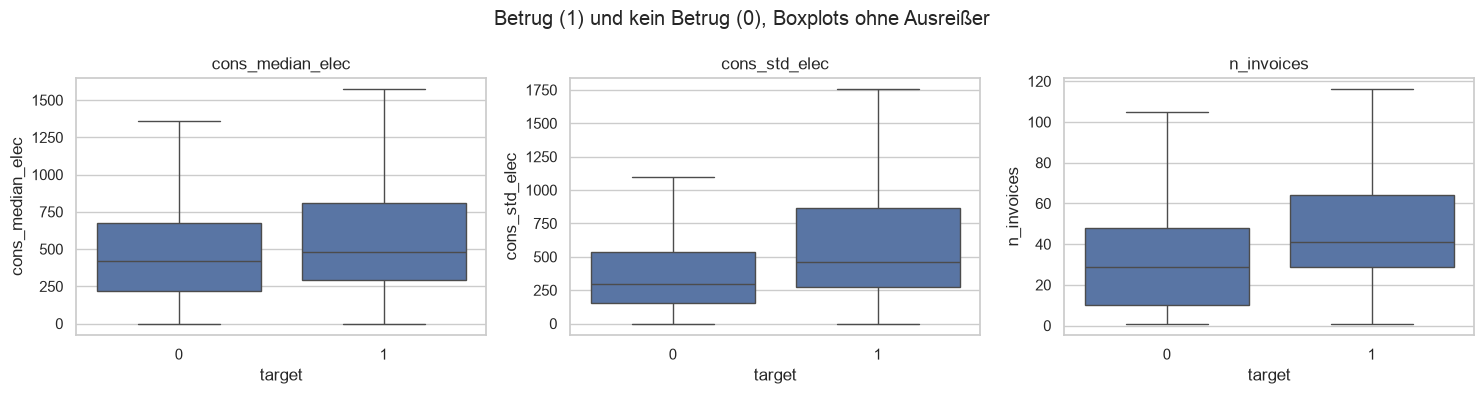

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, spalte in zip(axes, ["cons_median_elec", "cons_std_elec", "n_invoices"]):
    sns.boxplot(data=df_merged_train, x="target", y=spalte, showfliers=False, ax=ax)
    ax.set_title(spalte)

plt.suptitle("Betrug (1) und kein Betrug (0), Boxplots ohne Ausreißer")
plt.tight_layout()
plt.show()

**Was fällt auf?**
* Eigentlich hätten wir erwartet: Wer betrügt, hat offiziell **weniger** Verbrauch. Es ist aber umgekehrt, Betrüger haben etwas **mehr** Verbrauch und vor allem eine größere **Streuung**.
* Mögliche Erklärungen: Kunden mit viel Verbrauch werden vielleicht öfter kontrolliert und deshalb öfter erwischt. Und wer manchmal manipuliert und manchmal nicht, hat stark schwankenden Verbrauch.

**Entscheidung:** Nicht nur Mittelwerte, sondern auch die **Streuung** des Verbrauchs als Feature nutzen.

### 9.2 Zähler, Nullrechnungen und Zählerstand rückwärts

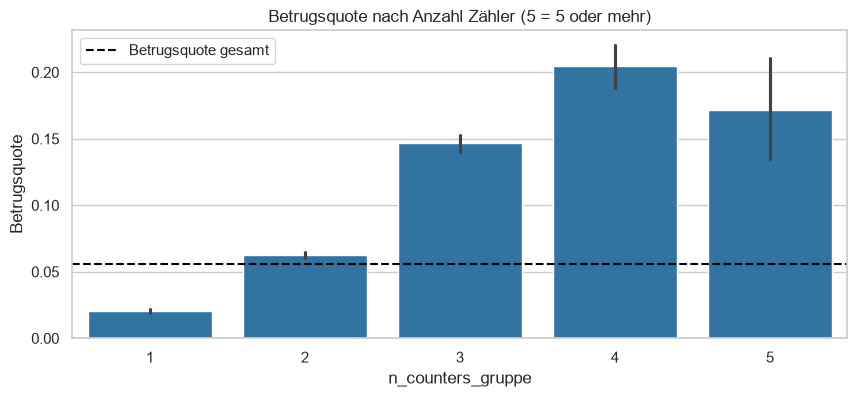

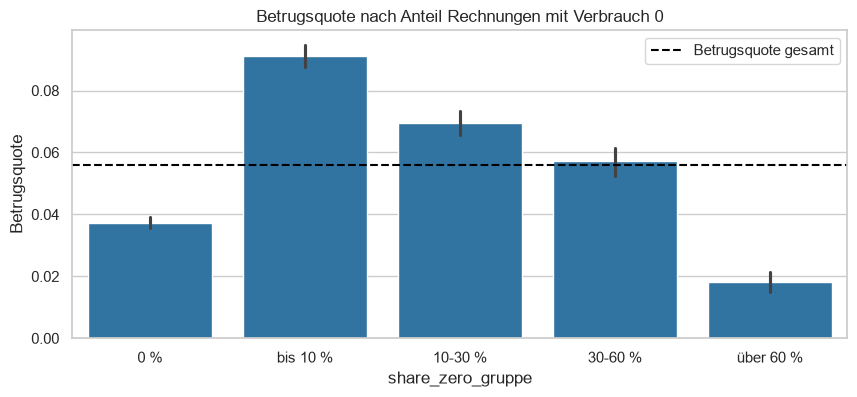

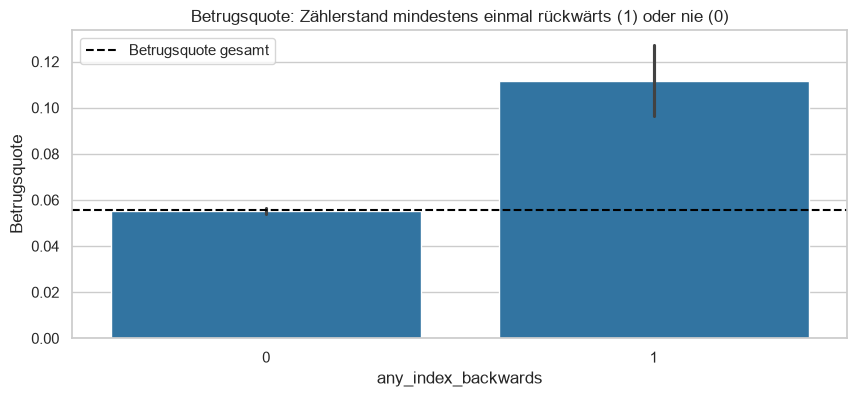

In [37]:
df_merged_train["n_counters_gruppe"] = df_merged_train["n_counters"].clip(upper=5)
df_merged_train["share_zero_gruppe"] = pd.cut(df_merged_train["share_zero"],
                                              bins=[-0.01, 0, 0.1, 0.3, 0.6, 1.0],
                                              labels=["0 %", "bis 10 %", "10-30 %", "30-60 %", "über 60 %"])

plot_betrugsquote(df_merged_train, "n_counters_gruppe", "Betrugsquote nach Anzahl Zähler (5 = 5 oder mehr)")
plot_betrugsquote(df_merged_train, "share_zero_gruppe", "Betrugsquote nach Anteil Rechnungen mit Verbrauch 0")
plot_betrugsquote(df_merged_train, "any_index_backwards", "Betrugsquote: Zählerstand mindestens einmal rückwärts (1) oder nie (0)")

In [38]:
display(tabelle_betrugsquote(df_merged_train, "n_counters_gruppe"))
display(tabelle_betrugsquote(df_merged_train, "share_zero_gruppe"))
tabelle_betrugsquote(df_merged_train, "any_index_backwards")

,Kunden,Betrugsquote
n_counters_gruppe,,
1,50696,0.020
2,42648,0.063
3,12375,0.147
4,2290,0.204
5,385,0.171


,Kunden,Betrugsquote
share_zero_gruppe,,
0 %,50243,0.037
bis 10 %,26160,0.091
10-30 %,15126,0.069
30-60 %,11147,0.057
über 60 %,5718,0.018


,Kunden,Betrugsquote
any_index_backwards,,
0,106924,0.055
1,1470,0.112


**Was fällt auf?**
* **Anzahl Zähler:** Mit einem Zähler 2 % Betrug, mit drei Zählern 15 %, mit vier 20 %. Das ist das stärkste Merkmal bisher. Mehr als zwei Zähler heißt meistens, dass ein Zähler ausgetauscht wurde. **Aber Achtung:** Vielleicht wurde der Zähler erst ausgetauscht, *nachdem* der Betrug entdeckt wurde. Dann wäre das Merkmal eine Folge vom Betrug und nicht ein Hinweis darauf. Das können wir mit den Daten nicht prüfen.
* **Verbrauch 0:** Kunden ohne Nullrechnung haben 3,7 % Betrug, Kunden mit wenigen Nullrechnungen (bis 10 %) haben 9,1 %, Kunden mit sehr vielen (über 60 %) nur 1,8 %. Der Zusammenhang geht also erst hoch und dann runter.
* **Zählerstand rückwärts:** 11,2 % statt 5,5 % Betrug, also doppelt so viel. Betrifft aber nur 1.470 Kunden.

### 9.3 Korrelation
Wir nehmen **Spearman** statt Pearson, weil der Verbrauch so schief ist und es viele Ausreißer gibt. Spearman rechnet mit Rängen und ist deshalb robuster.

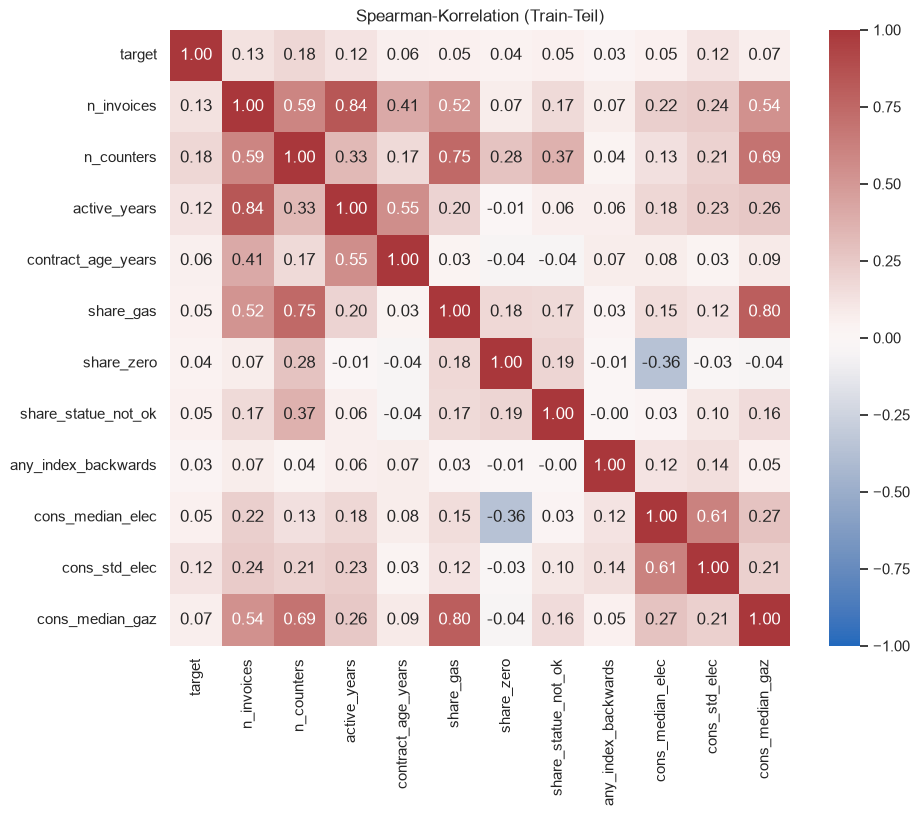

n_counters             0.179781
n_invoices             0.129819
active_years           0.123607
cons_std_elec          0.123553
cons_median_gaz        0.068759
contract_age_years     0.059543
share_gas              0.053158
cons_median_elec       0.051469
share_statue_not_ok    0.048402
share_zero             0.039647
any_index_backwards    0.028454
Name: target, dtype: float64

In [39]:
korr_spalten = ["target", "n_invoices", "n_counters", "active_years", "contract_age_years",
                "share_gas", "share_zero", "share_statue_not_ok", "any_index_backwards",
                "cons_median_elec", "cons_std_elec", "cons_median_gaz"]

korr = df_merged_train[korr_spalten].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(korr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
plt.title("Spearman-Korrelation (Train-Teil)")
plt.show()

korr["target"].drop("target").sort_values(ascending=False)

**Was fällt auf?**
* Mit `target` hängt jedes Merkmal allein nur schwach zusammen (höchstens 0,18 bei `n_counters`). Das ist bei so wenig Betrug normal. Trotzdem steigt die Betrugsquote bei `n_counters` von 2 % auf 20 % (siehe 9.2). Ein Modell muss viele schwache Merkmale kombinieren.
* Einige Merkmale hängen stark miteinander zusammen, z. B. `n_invoices` und `active_years` (0,84) oder `share_gas` und `cons_median_gaz` (0,80). Sie messen zum Teil dasselbe. Für die logistische Regression sollten wir nicht alle gleichzeitig nehmen.

## 10 · Bereinigte Daten speichern
Wir speichern die Tabelle mit einer Zeile pro Kunde als `data/fd_cleaned.csv`. Das nächste Notebook (`05_baseline.ipynb`) baut darauf auf, damit man nicht jedes Mal die 4,5 Mio. Rechnungen neu laden muss.

Die Hilfsspalten aus Abschnitt 6 und 9 (z. B. `start_5_jahre`) sind nicht drin, die waren nur für die Grafiken. `first_invoice` und `last_invoice` lassen wir weg, weil `active_years` dieselbe Info als Zahl enthält.

In [40]:
df_cleaned = df_merged.drop(columns=["first_invoice", "last_invoice"])

print(f"Zeilen: {df_cleaned.shape[0]:,}   Spalten: {df_cleaned.shape[1]}")
print("Fehlende Werte:", df_cleaned.isna().sum().sum())
df_cleaned.dtypes

Zeilen: 135,493   Spalten: 20
Fehlende Werte: 0


disrict                         int64
client_id                         str
client_catg                     int64
region                          int64
creation_date          datetime64[us]
target                          int64
n_invoices                      int64
n_counters                      int64
share_gas                     float64
share_zero                    float64
any_index_backwards             int64
share_statue_not_ok           float64
cons_median_elec              float64
cons_mean_elec                float64
cons_std_elec                 float64
cons_median_gaz               float64
cons_mean_gaz                 float64
cons_std_gaz                  float64
contract_age_years            float64
active_years                  float64
dtype: object

In [41]:
df_cleaned.to_csv(DATA_DIR / "fd_cleaned.csv", index=False)
print("Gespeichert: data/fd_cleaned.csv")

Gespeichert: data/fd_cleaned.csv


## 11 · Fazit

| | |
|---|---|
| Kunden | 135.493 (Train 108.394, Test 27.099) |
| Rechnungen | 4.476.738 (nach 11 gelöschten Duplikaten), Median 30 pro Kunde |
| Betrugsquote | 5,58 % (in Train und Test gleich) |
| Strom / Gas | 69 % / 31 % der Rechnungen, 54 % der Kunden nur Strom, 45 % beides |
| Stärkste Merkmale | Anzahl Zähler (2 % → 20 %), Kategorie 51 (17,5 %), Vertrag vor 2015, Zählerstand rückwärts (11 %), Region 103 (10 %) |
| Betrüger | mehr Rechnungen, mehr Zähler, etwas mehr Verbrauch, viel mehr Streuung |

**Was wir bereinigt haben:**
* 11 doppelte Rechnungen gelöscht
* `target` als `int`, Datumsspalten als `datetime`
* ungültige Werte in `counter_statue` auf `NaN` gesetzt
* Verbrauch aus den vier Tarifstufen addiert
* fehlende Verbrauchswerte (kein Gas / kein Strom) mit 0 gefüllt

**Für das Modell:**
* Metrik: ROC-AUC, dazu Recall und Precision. Keine Accuracy.
* Split aus `data/fd_split.csv` benutzen, Test-Teil erst am Ende.
* Region und Kategorie als Kategorien (One-Hot-Encoding).
* Für die logistische Regression den Verbrauch logarithmieren und nicht alle ähnlichen Merkmale gleichzeitig nehmen.

**Nächster Schritt:** `05_baseline.ipynb` mit `data/fd_cleaned.csv`.